This notebook runs Exercises 3 to 6 in order, on our own photo, shows every result of the report and saves every figure in `figures/`. Exercises 1 and 2 are theoretical: their proof and derivation are in `A1_Report.pdf`.

**How to run:** keep this notebook, `src/`, `data/`, and `figures/` folders in the same directory, then *Restart* and *Run All*. Every cell only uses the functions in `src/`.

## 0. Setup

The first cell installs the three packages the notebook uses. The second one sets the paths and imports our src.

In [1]:
%pip install -q opencv-python numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

WORK_DIR = Path(".").resolve()
DATA_DIR = WORK_DIR / "data"
FIG_DIR = WORK_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(WORK_DIR / "src"))

import a1_image as im
import a1_gabor as gab
import a1_canny as can
import a1_pyramids as pyr

print("OpenCV", cv2.__version__, "| NumPy", np.__version__)


OpenCV 5.0.0 | NumPy 2.5.4


## Exercise 3 — Photo, resize to 448×336, read and show

We photographed a cluttered living room at 5712×4284. Same 4:3 proportions as 448×336, so nothing is distorted. `INTER_AREA` averages each block of about 13×13 pixels, which avoids aliasing on fine detail.

Figures: `fig3_scene.png`, `fig3_gray.png`.

photo: (4284, 5712, 3) -> scene: (336, 448, 3) | grey: (336, 448) uint8


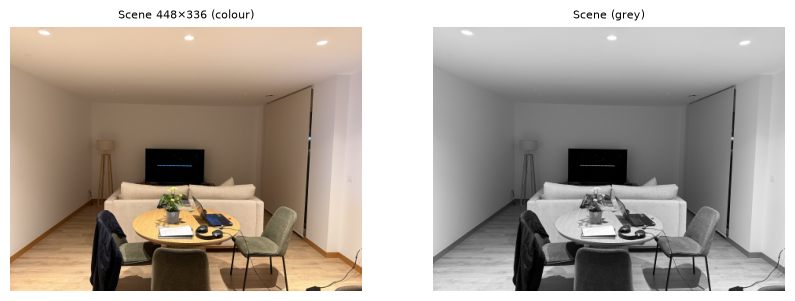

In [3]:
photo = im.load_bgr(DATA_DIR / "my_scene.png")
SCENE = im.resize_to(photo, (448, 336))
GRAY = im.to_gray(SCENE)
print("photo:", photo.shape, "-> scene:", SCENE.shape, "| grey:", GRAY.shape, GRAY.dtype)

im.save_figure(SCENE, DATA_DIR / "scene_448x336.png")
im.save_figure(SCENE, FIG_DIR / "fig3_scene.png")
im.save_figure(GRAY, FIG_DIR / "fig3_gray.png")

fig = im.show_images([SCENE, GRAY], ["Scene 448×336 (colour)", "Scene (grey)"], cols=2, figsize=(10, 4))
plt.show()

## Exercise 4 — Gabor filter at 4 orientations, maximum, 3 parameter sets

Four orientations (0°, 45°, 90°, 135°), combined with the per-pixel maximum of the absolute responses, so dark and bright structures both stand out. The three sets only change the scale: the larger the wavelength, the wider the structures the filter responds to.

Figures: `fig4a_kernels.png` (the 12 kernels), `fig4b_set1.png` (the 4 responses of the fine set and their combination), `fig4c_sets.png` (the 3 sets).

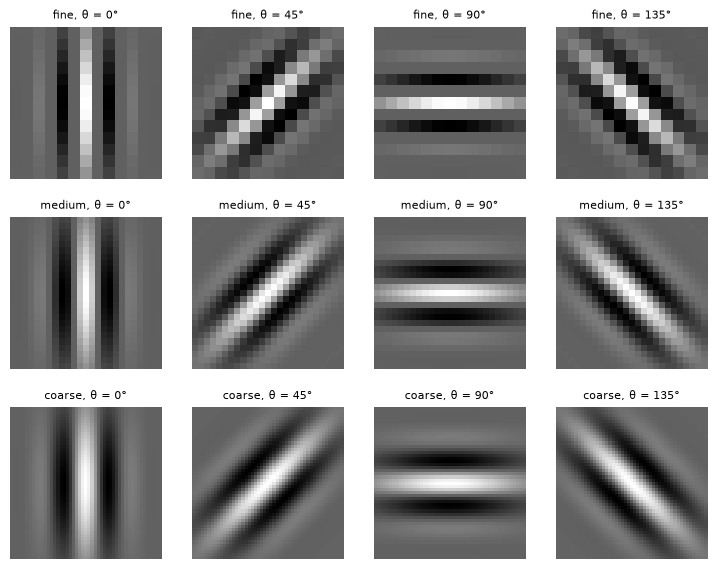

In [4]:
THETAS = np.deg2rad([0, 45, 90, 135])
SET_1 = {"ksize": 13, "sigma": 2.0, "lambd": 4.0,  "gamma": 0.5, "psi": 0.0}
SET_2 = {"ksize": 25, "sigma": 4.0, "lambd": 8.0,  "gamma": 0.5, "psi": 0.0}
SET_3 = {"ksize": 49, "sigma": 8.0, "lambd": 16.0, "gamma": 0.5, "psi": 0.0}
SETS = {"fine": SET_1, "medium": SET_2, "coarse": SET_3}

kernels, titles = [], []
for name, P in SETS.items():
    for th in THETAS:
        kernels.append(gab.gabor_kernel(theta=th, **P))
        titles.append(f"{name}, θ = {np.rad2deg(th):.0f}°")

fig = im.show_images(kernels, titles, cols=4, figsize=(9, 7))
im.save_figure(fig, FIG_DIR / "fig4a_kernels.png", dpi=200)
plt.show()

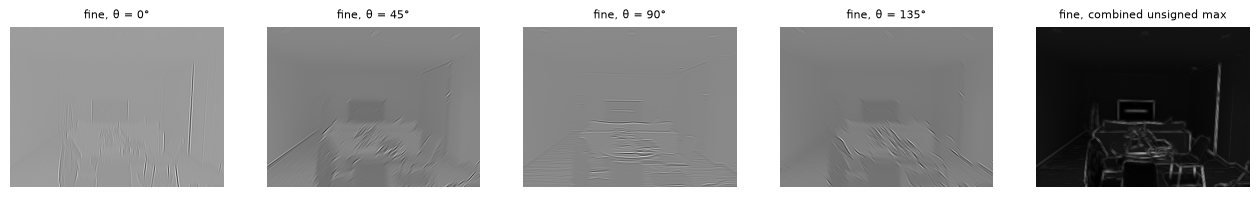

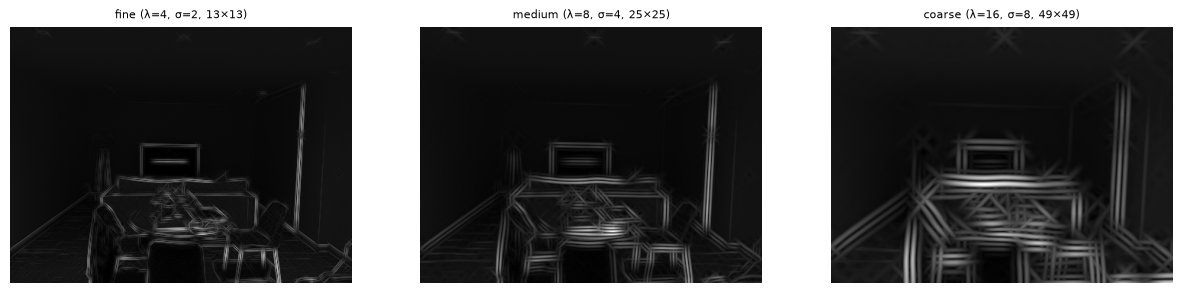

In [5]:
GABOR_MAX_1_ABS = gab.combine_max(abs(gab.gabor_bank(GRAY, SET_1, THETAS)))
GABOR_MAX_2_ABS = gab.combine_max(abs(gab.gabor_bank(GRAY, SET_2, THETAS)))
GABOR_MAX_3_ABS = gab.combine_max(abs(gab.gabor_bank(GRAY, SET_3, THETAS)))
GABOR_MAX = GABOR_MAX_1_ABS

R1 = gab.gabor_bank(GRAY, SET_1, THETAS)

images, titles = [], []
for resp, th in zip(R1, THETAS):
    images.append(resp)
    titles.append(f"fine, θ = {np.rad2deg(th):.0f}°")
images.append(im.to_uint8(GABOR_MAX_1_ABS))
titles.append("fine, combined unsigned max")

fig = im.show_images(images, titles, cols=5, figsize=(16, 2.8))
im.save_figure(fig, FIG_DIR / "fig4b_set1.png", dpi=200)
plt.show()

fig = im.show_images([im.to_uint8(GABOR_MAX_1_ABS), im.to_uint8(GABOR_MAX_2_ABS), im.to_uint8(GABOR_MAX_3_ABS)],
                     ["fine (λ=4, σ=2, 13×13)", "medium (λ=8, σ=4, 25×25)", "coarse (λ=16, σ=8, 49×49)"], cols=3, figsize=(15, 4))
im.save_figure(fig, FIG_DIR / "fig4c_sets.png", dpi=200)
plt.show()

## Exercise 5 — Canny, compared with Gabor

The median heuristic gives a starting pair. Lowering `low` to 10 completes the broken contours (door frame, floor–wall line, table, chairs) through hysteresis, and the walls and floor stay empty. Without the blur, texture and noise become edges.

Figures: `fig5a_canny.png` (the 4 settings), `fig5a_canny_auto.png`, `fig5a_canny_Ksize0.png`, `fig5a_canny_overlay.png`, `fig5b_compare.png`.

auto thresholds: low=99, high=196


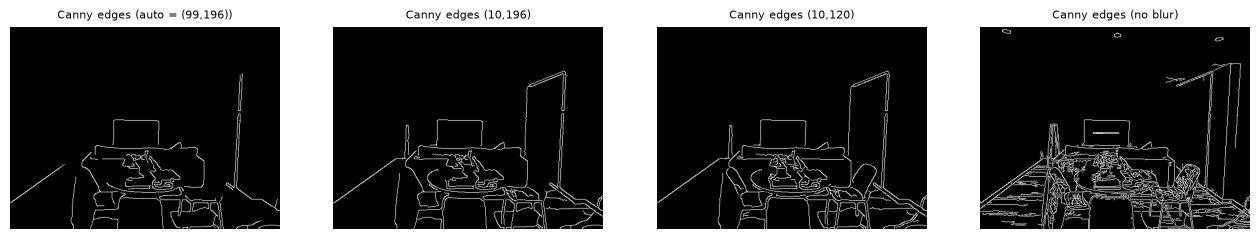

In [6]:
low, high = can.auto_thresholds(GRAY)
print(f"auto thresholds: low={low}, high={high}")

CANNY_AUTO = can.canny_edges(GRAY, low, high, blur_ksize=5, blur_sigma=1.4)
CANNY_1 = can.canny_edges(GRAY, 10, 196, blur_ksize=5, blur_sigma=1.4)
CANNY_3 = can.canny_edges(GRAY, 10, 120, blur_ksize=5, blur_sigma=1.4)
CANNY_NO_BLUR = can.canny_edges(GRAY, 10, 120, blur_ksize=0)

CANNY = CANNY_3

fig1 = im.show_images([CANNY_AUTO, CANNY_1, CANNY_3, CANNY_NO_BLUR],
                      [f"Canny edges (auto = ({low},{high}))", "Canny edges (10,196)", "Canny edges (10,120)", "Canny edges (no blur)"],
                      cols=4, figsize=(16, 3.5))
im.save_figure(fig1, FIG_DIR / "fig5a_canny.png", dpi=200)
plt.show()

im.save_figure(CANNY_AUTO, FIG_DIR / "fig5a_canny_auto.png")
im.save_figure(CANNY_NO_BLUR, FIG_DIR / "fig5a_canny_Ksize0.png")

**Comparison.** Canny gives 1-pixel lines (binary), Gabor gives wide bands of continuous values. On the door frame, the red Canny line sits in the middle of the Gabor band (non-maximum suppression keeps only the peak). On the floor, Gabor responds to the wooden texture while Canny marks nothing.

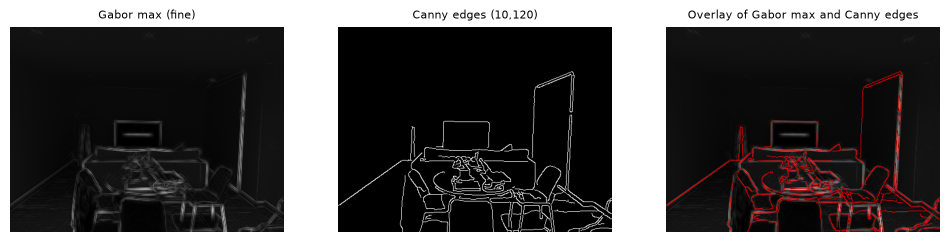

In [7]:
OVERLAY = can.overlay_edges(im.to_uint8(GABOR_MAX), CANNY)
im.save_figure(OVERLAY, FIG_DIR / "fig5a_canny_overlay.png")

fig = im.show_images([GABOR_MAX, CANNY, OVERLAY],
                     ["Gabor max (fine)", "Canny edges (10,120)", "Overlay of Gabor max and Canny edges"], cols=3, figsize=(12, 4))
im.save_figure(fig, FIG_DIR / "fig5b_compare.png", dpi=200)
plt.show()

## Exercise 6 — Gaussian and Laplacian pyramids

Each Gaussian level is the previous one blurred and halved, so it keeps only the low frequencies. Each Laplacian level keeps the details that one more blur removes: the high frequencies are in L0 (floor planks, chair fabric, cables, the TV light bar, the ceiling lights), and the low frequencies in the top level L4 = G4 (the smooth walls and ceiling, close to zero in every other level).

Figures: `fig6a_gaussian.png`, `fig6b_laplacian.png` (each level drawn at its real size, one shared grey scale for L0–L3, mid-grey = 0).

sizes: [(336, 448), (168, 224), (84, 112), (42, 56), (21, 28)]


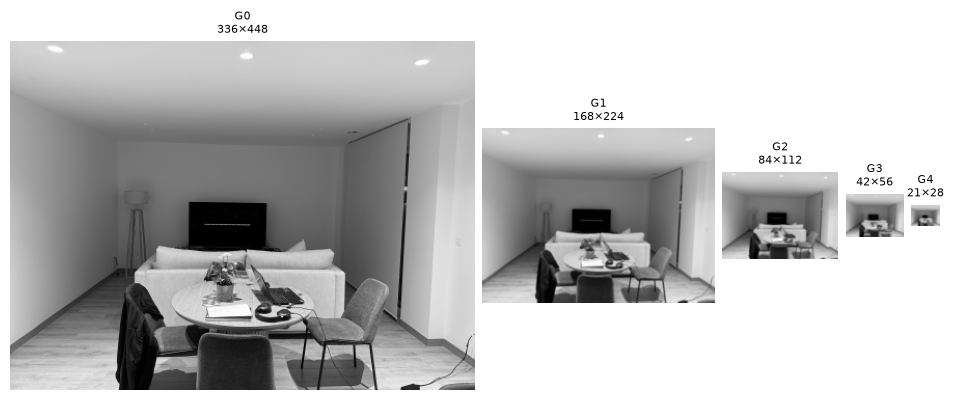

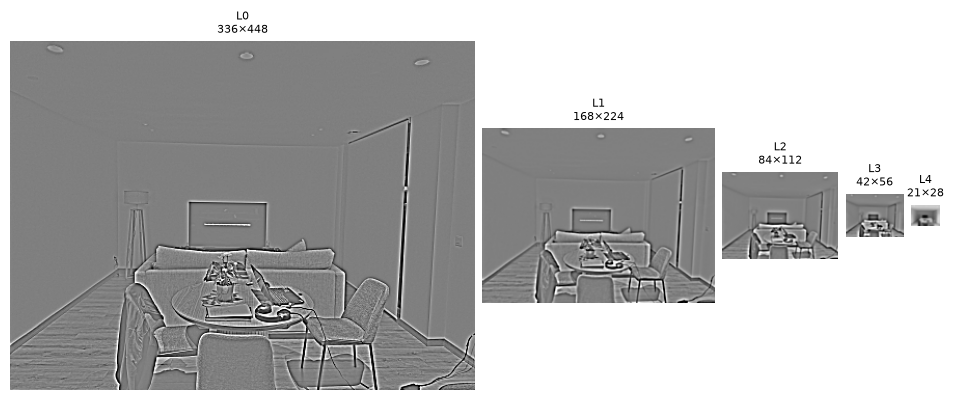

In [8]:
G = pyr.gaussian_pyramid(GRAY, 4)
L = pyr.laplacian_pyramid(G)
print("sizes:", [g.shape for g in G])

widths = []
for g in G:
    widths.append(g.shape[1])

fig, axs = plt.subplots(1, len(G), figsize=(12, 5), gridspec_kw={"width_ratios": widths, "wspace": 0.04})
for i, g in enumerate(G):
    axs[i].imshow(g, cmap="gray", vmin=0, vmax=255)
    axs[i].set_title(f"G{i}\n{g.shape[0]}×{g.shape[1]}", fontsize=8)
    axs[i].axis("off")
im.save_figure(fig, FIG_DIR / "fig6a_gaussian.png", dpi=200)
plt.show()

lim = 0
for l in L[:-1]:
    lim = max(lim, np.percentile(np.abs(l), 99))

fig, axs = plt.subplots(1, len(L), figsize=(12, 5), gridspec_kw={"width_ratios": widths, "wspace": 0.04})
for i, l in enumerate(L):
    if i < len(L) - 1:
        axs[i].imshow(l, cmap="gray", vmin=-lim, vmax=lim)
    else:
        axs[i].imshow(l, cmap="gray", vmin=0, vmax=255)
    axs[i].set_title(f"L{i}\n{l.shape[0]}×{l.shape[1]}", fontsize=8)
    axs[i].axis("off")
im.save_figure(fig, FIG_DIR / "fig6b_laplacian.png", dpi=200)
plt.show()